# Lo que un potencial moldeado le pide al holograma

**Pregunta:** ¿Qué le pide al holograma un potencial en forma de disco que no le piden nueve trampas puntuales, y hasta dónde llega Gerchberg-Saxton simple sobre el disco del caso C04 en sus 30 iteraciones?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** notebook 01 del tema 03-gerchberg-saxton (el lazo sobre trampas puntuales)
- **Tiempo de lectura:** unos 35 minutos; el notebook se ejecuta en unos 20 segundos

## Objetivos

Un arreglo de trampas ópticas pide luz en unos pocos puntos y le importa cuánta luz recibe cada uno. Un potencial moldeado, un disco plano de luz que mantiene un gas con densidad uniforme, pide un perfil: miles de bins focales que deben llevar la misma intensidad. Este notebook pone las dos peticiones lado a lado, sobre el mismo modulador espacial de luz (SLM) y con el mismo algoritmo. Contará lo que restringe cada objetivo, medirá el inicio del motor y las primeras iteraciones de Gerchberg-Saxton simple sobre el disco, evaluará el resultado a mano con el error del producto y comparará la dispersión del disco con la de nueve trampas. Al final sabrá por qué un método excelente para trampas deja un disco cuya intensidad se equivoca en 44 por ciento, y qué dice y qué no dice ese número.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 scipy==1.18.1
```

DinHot no publica un paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, y luego los módulos del pipeline por su ruta
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, traps
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m04_gs

for name in ("numpy", "matplotlib", "scipy"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
scipy 1.18.1


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, sin conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C04: un disco de 15 um de radio en un SLM de 256 por 256 píxeles de 20 um a 850 nm. El dispositivo del caso (8 bits y crosstalk) no se usa aquí; el notebook corre el SLM ideal.

In [2]:
# el caso C04 da el SLM, el haz y el disco; el registro se lee con el lector del contrato
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C04_disc_crosstalk"]
setup = setup_of(rec)
disc = target_of(rec)
seed = rec["seed"]
bin_um = geometry.focal_bin_m(setup) * 1e6
print(f"SLM {setup.n_pix} x {setup.n_pix} píxeles, malla focal {setup.n_fft} x {setup.n_fft} bins")
print(f"un bin = {bin_um:.3f} um")
print(f"radio del disco {rec['target']['radius_um']} um = {rec['target']['radius_um'] / bin_um:.1f} bins")
print(f"bins en la forma {int((disc.amplitude > 0).sum())}, bins en la región de señal {int(disc.mask.sum())}")

SLM 256 x 256 píxeles, malla focal 512 x 512 bins
un bin = 0.498 um
radio del disco 15.0 um = 30.1 bins
bins en la forma 2861, bins en la región de señal 3389


## Método

**El modelo directo.** El SLM muestra una fase $\phi$ bajo un haz gaussiano de amplitud $A$. Una lente de distancia focal $f$ convierte el campo del SLM en su transformada de Fourier: el campo focal es $E = \mathcal{F}\{A\,e^{i\phi}\}$ sobre una grilla de bins, y la luz que cae en un bin es $|E|^2$. El caso rellena el SLM con ceros hasta una grilla focal de 512 por 512 bins, de modo que un bin es menor que el rasgo más pequeño que el SLM resuelve (una celda de resolución son `pad` = 2 bins). Todo lo que sigue pasa por esa única función del motor, `fft_focal_field`.

**El objetivo.** Un arreglo de trampas da $M$ posiciones y $M$ pesos. Un objetivo con forma da una amplitud $T$ sobre los bins de la forma y una región de señal (SR): la forma más un margen oscuro de tres bins a su alrededor. El método debe lograr que $|E|^2$ sea igual a $T^2$ en la forma, salvo una escala global, porque la potencia se conserva y el objetivo solo fija proporciones.

**El lazo.** M04 es Gerchberg-Saxton simple. Una iteración reemplaza la amplitud focal por el objetivo conservando la fase, vuelve al SLM y conserva allí solo la fase: $G = T\,e^{i\arg E}$ dentro de la SR y $0$ fuera, y luego $\phi \leftarrow \arg \mathcal{F}^{-1}\{G\}$. Es la regla de región mixta de Pasienski y DeMarco (2008, Ec. 1, https://doi.org/10.1364/OE.16.002176) con el parámetro de mezcla en 1, que es como el M04 del producto trata un objetivo con forma. Para trampas puntuales el mismo paso es el lazo de Di Leonardo et al. (2007, https://doi.org/10.1364/OE.15.001913).

**El error.** Sobre la región de medida, la forma erosionada en una celda de resolución, el producto evalúa un holograma con $\eta = \sqrt{\langle ((sI - T^2)/T^2)^2 \rangle}$ y $s = \sum T^2 / \sum I$ (Pasienski y DeMarco 2008, Ec. 2). Es una desviación relativa por bin, de modo que un resultado con $\eta = 0.44$ tiene bins equivocados en torno a 44 por ciento del objetivo en promedio, en cualquiera de los dos sentidos.

El primer paso cuenta lo que pide cada objetivo. La celda construye nueve trampas puntuales en una grilla de 3 por 3, separadas 8 um, halla la región de medida del disco e imprime cuántos números fija cada objetivo frente al número de fases que ofrece el SLM.

In [3]:
# qué restringe cada objetivo: nueve trampas puntuales frente a los bins del disco
nine = traps.square_grid(3, 3, 8.0)
structure = np.ones((2 * setup.pad + 1,) * 2, dtype=bool)
core = ndimage.binary_erosion(disc.amplitude > 0, structure=structure)
print(f"trampas puntuales: {len(nine)} intensidades por fijar, separadas {8.0 / bin_um:.1f} bins")
print(f"disco: {int(core.sum())} bins por fijar (la forma erosionada en {setup.pad} bins)")
print(f"fases libres en el SLM: {setup.n_pix**2}")
per_phase = (len(nine) / setup.n_pix**2, core.sum() / setup.n_pix**2)
print(f"restricciones por fase libre: puntos {per_phase[0]:.5f}, disco {per_phase[1]:.4f}")

trampas puntuales: 9 intensidades por fijar, separadas 16.1 bins
disco: 2389 bins por fijar (la forma erosionada en 2 bins)
fases libres en el SLM: 65536
restricciones por fase libre: puntos 0.00014, disco 0.0365


Nueve trampas fijan nueve intensidades y el disco fija 2389 bins, unas 265 veces más, con las mismas 65536 fases. La razón entre restricciones y libertades pasa de 0,00014 a 0,0365. Un arreglo de trampas está muy poco restringido, y un holograma que cumple nueve números tiene margen de sobra para igualarlos. El disco emplea 3,65 por ciento de las libertades solo en fijar intensidades, y cada uno de sus bins tiene una tolerancia, porque un potencial plano es una afirmación sobre todos ellos.

El segundo paso es la cifra de mérito a mano. La celda escribe el error de la sección Método como función de una fase: toma el campo focal del motor, escala la intensidad para que el objetivo y el holograma lleven el mismo total en la región de medida y conserva la desviación relativa de cada bin. Luego evalúa el holograma de inicio del motor, una lente de Fresnel de 20 ondas en el borde de la apertura, que es la fase de la que parte M04 cuando no se le da ninguna.

In [4]:
# la cifra de mérito a mano: escalar la intensidad al objetivo y luego la desviación relativa en la región de medida
def deviation_map(phi):
    intensity = np.abs(forward.fft_focal_field(phi, setup)) ** 2
    wanted = disc.amplitude**2
    scale = wanted[core].sum() / intensity[core].sum()
    deviation = np.zeros_like(intensity)
    deviation[core] = (scale * intensity[core] - wanted[core]) / wanted[core]
    return deviation, scale * intensity, intensity[disc.mask].sum() / setup.n_pix**2


x, y = geometry.slm_grid(setup)
fresnel = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
dev_start, _, share_start = deviation_map(fresnel)
error_start = np.sqrt(np.mean(dev_start[core] ** 2))
print(f"error del arranque, una lente de Fresnel de 20 ondas: {error_start:.4f}")
print(f"fracción de potencia de ese arranque en la región de señal: {share_start:.4f}")

error del arranque, una lente de Fresnel de 20 ondas: 0.0322
fracción de potencia de ese arranque en la región de señal: 0.0887


El inicio obtiene un error de 0,0322, mucho mejor que todo lo que sigue, y la línea siguiente dice por qué no puede ser la respuesta: solo 0,0887 de la potencia cae en la región de señal. Una lente de Fresnel reparte el haz en un punto ancho y suave, y el disco está en la cima plana de ese punto, de modo que dentro del disco el perfil es casi constante. El error se mide después de reescalar al objetivo, así que ignora cuánta luz hay. Por eso el producto informa el error junto con la fracción de potencia en la región de señal, y este notebook hace lo mismo de aquí en adelante.

El tercer paso corre M04 sobre el disco. La celda continúa una corrida en tres llamadas para guardar el holograma tras 1, 5 y 30 iteraciones, lo que da el mismo resultado que una sola corrida de 30 porque el único estado del lazo es la fase. Para cada punto de parada imprime el error calculado a mano junto al que el método registra en su historial, y la fracción de potencia en la región de señal.

In [5]:
# Gerchberg-Saxton simple (M04) sobre el disco, continuado desde su propia fase: iteraciones 1, 5 y 30
phis, history, done, phi_now = {}, [], 0, None
for stop in (1, 5, 30):
    res = m04_gs.run(setup, disc, budget=Budget(stop - done), rng=Rng(seed), init=phi_now)
    phi_now, done = res.phi, stop
    phis[stop] = phi_now
    history += res.history
for k in (1, 5, 30):
    own = np.sqrt(np.mean(deviation_map(phis[k])[0][core] ** 2))
    print(f"iteración {k:2d}: error a mano {own:.4f}, error del método {history[k - 1]['error']:.4f}, "
          f"fracción de potencia en la región de señal {history[k - 1]['efficiency']:.4f}")

iteración  1: error a mano 1.1564, error del método 1.1564, fracción de potencia en la región de señal 0.9124
iteración  5: error a mano 0.5855, error del método 0.5855, fracción de potencia en la región de señal 0.9435
iteración 30: error a mano 0.4411, error del método 0.4411, fracción de potencia en la región de señal 0.9621


Los dos errores coinciden en cuatro dígitos en cada punto de parada, así que la función escrita a mano es la medida del producto. El error es 1,1564 tras una iteración, 0,5855 tras cinco y 0,4411 tras treinta, mientras la potencia en la región de señal sube de 0,9124 a 0,9621. La figura dibuja cómo se ven esos números: la intensidad a lo largo del eje x por el centro del disco, escalada al objetivo, para el inicio y para los tres hologramas.

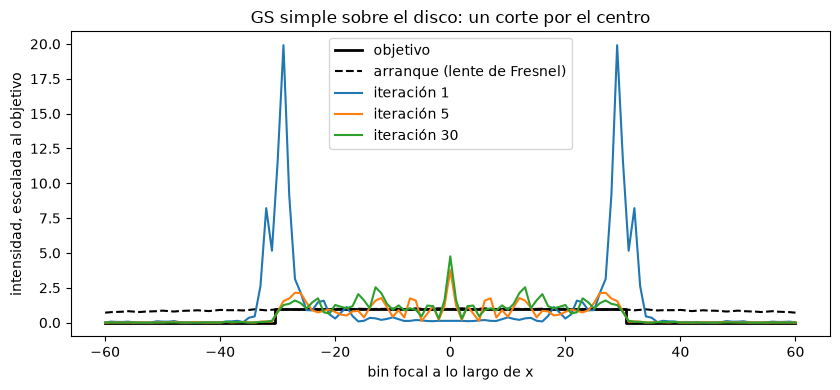

In [6]:
# la intensidad a lo largo del eje x por el centro, escalada al objetivo, tras 1, 5 y 30 iteraciones
c = setup.n_fft // 2
span = np.arange(c - 60, c + 61)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.step(span - c, (disc.amplitude[c, span] ** 2), where="mid", color="k", lw=2, label="objetivo")
ax.plot(span - c, deviation_map(fresnel)[1][c, span], "k--", label="arranque (lente de Fresnel)")
for k in (1, 5, 30):
    ax.plot(span - c, deviation_map(phis[k])[1][c, span], label=f"iteración {k}")
ax.set_xlabel("bin focal a lo largo de x")
ax.set_ylabel("intensidad, escalada al objetivo")
ax.set_title("GS simple sobre el disco: un corte por el centro")
ax.legend()
fig.tight_layout()
plt.show()

El inicio punteado es casi plano a lo largo del corte pero se extiende bastante más allá del borde, y ahí va su potencia. Tras una iteración la luz se ha reunido en el borde del disco, con picos unas veinte veces el objetivo en el borde y casi nada adentro: el lazo fuerza la amplitud dentro del disco al objetivo, y el campo que el SLM puede hacer en realidad la pone sobre todo en el borde. Tras cinco y treinta iteraciones el interior se llena, pero con ondulaciones desde un tercio del objetivo hasta dos veces y media su valor y un pico de unas 4,7 veces en el centro, que es el moteado que deja un holograma de solo fase cuando se fuerza cada bin del disco. La figura muestra un corte a lo largo de un eje y no dice nada del patrón bidimensional de las ondulaciones, que el próximo gráfico dibuja.

El cuarto paso es la comparación que pide la pregunta. La celda corre el mismo M04 sobre las nueve trampas con la misma semilla y el mismo presupuesto e imprime su eficiencia, su uniformidad y su dispersión relativa, junto a los mismos tres números del disco.

In [7]:
# el mismo algoritmo sobre nueve trampas puntuales, 30 iteraciones, para comparar la dispersión
points = m04_gs.run(setup, Target.from_traps(nine), budget=Budget(30), rng=Rng(seed))
last = points.history[-1]
print(f"nueve trampas: eficiencia {last['efficiency']:.4f}, uniformidad {last['uniformity']:.4f}, "
      f"dispersión relativa {last['rel_std']:.2f} %")
print(f"disco: potencia en la región de señal {history[-1]['efficiency']:.4f}, "
      f"dispersión relativa {history[-1]['rel_std']:.2f} %")

nueve trampas: eficiencia 0.8190, uniformidad 0.8926, dispersión relativa 6.81 %
disco: potencia en la región de señal 0.9621, dispersión relativa 44.11 %


Sobre nueve trampas el lazo llega a una dispersión relativa de 6,81 por ciento y una uniformidad de 0,8926, con 0,8190 de la potencia en las trampas. Sobre el disco pone 0,9621 de la potencia en la región de señal, más que para las trampas, y obtiene una dispersión relativa de 44,11 por ciento sobre los bins del disco. La uniformidad de las trampas, construida con la trampa más brillante y la más tenue, no es un número para una forma: sobre miles de bins la fijan dos bins extremos, y el producto evalúa una forma solo por su error y por la potencia en su región de señal. El mismo algoritmo da un buen arreglo y un mal disco. La potencia no es el problema, ya que el disco tiene más en su región de señal; el problema es que el disco pide un holograma cuya luz sea plana sobre 2389 bins a la vez. El último gráfico mapea dónde se equivoca el disco y sigue la dispersión de ambos objetivos a lo largo de las iteraciones.

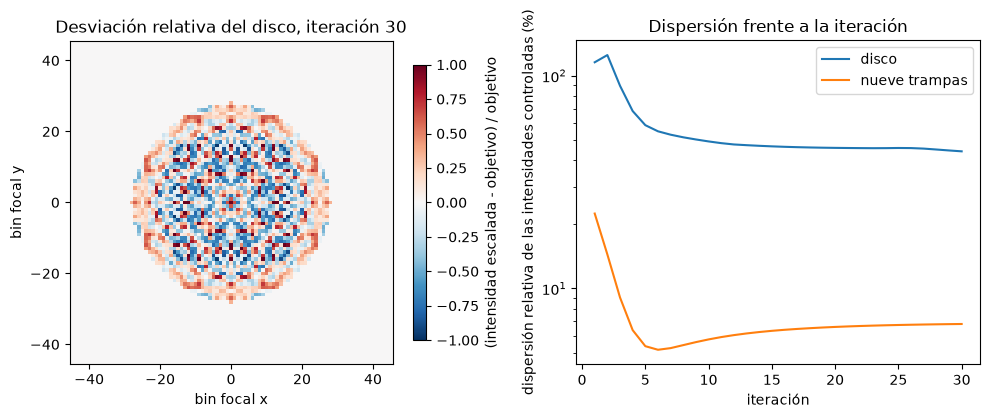

In [8]:
# el mapa de desviación del disco tras 30 iteraciones, y la dispersión de ambos objetivos frente a la iteración
dev30 = deviation_map(phis[30])[0]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.2))
window = np.s_[c - 45:c + 46, c - 45:c + 46]
clipped = np.clip(dev30[window], -1, 1)
shown = left.imshow(clipped, cmap="RdBu_r", vmin=-1, vmax=1, origin="lower", extent=(-45.5, 45.5, -45.5, 45.5))
left.set_xlabel("bin focal x")
left.set_ylabel("bin focal y")
left.set_title("Desviación relativa del disco, iteración 30")
fig.colorbar(shown, ax=left, label="(intensidad escalada - objetivo) / objetivo", shrink=0.85)
right.semilogy(range(1, len(history) + 1), [h["rel_std"] for h in history], label="disco")
right.semilogy(range(1, len(points.history) + 1), [h["rel_std"] for h in points.history], label="nueve trampas")
right.set_xlabel("iteración")
right.set_ylabel("dispersión relativa de las intensidades controladas (%)")
right.set_title("Dispersión frente a la iteración")
right.legend()
fig.tight_layout()
plt.show()

A la izquierda, el mapa de desviación del disco tras treinta iteraciones es un reticulado simétrico de celdas rojas y azules que llega a los límites de la escala, más y menos 100 por ciento, en el interior: no hay una región correcta y unas pocas equivocadas, todo el disco lleva el moteado. A la derecha, la dispersión de las nueve trampas baja de 10 por ciento en cinco iteraciones y luego sube un poco, mientras la del disco parte sobre 100 por ciento, cae rápido durante diez iteraciones y luego se aplana cerca de 44 por ciento. El disco dejó de mejorar, lo que apunta al algoritmo y no al presupuesto. El gráfico no dice si algún holograma puede hacerlo mejor en este disco, solo que este lazo con esta restricción se queda donde está.

El último paso mira el borde. La región de medida deja fuera los bins a una celda de resolución del borde, porque ningún holograma puede colocar un borde nítido entre dos bins que la óptica no distingue. La celda evalúa el mismo holograma en la región erosionada y en toda la forma, para ver si esa elección esconde una parte grande del error.

In [9]:
# el borde: el mismo holograma evaluado en toda la forma y en la región de medida erosionada
whole = disc.amplitude > 0
wanted = disc.amplitude**2
intensity = np.abs(forward.fft_focal_field(phis[30], setup)) ** 2
for label, region in (("región de medida erosionada", core), ("forma completa", whole)):
    scale = wanted[region].sum() / intensity[region].sum()
    error = np.sqrt(np.mean(((scale * intensity[region] - wanted[region]) / wanted[region]) ** 2))
    print(f"{label}: {int(region.sum())} bins, error {error:.4f}")

región de medida erosionada: 2389 bins, error 0.4411
forma completa: 2861 bins, error 0.4306


## Resultados

**Respuesta:** Un disco pide un perfil plano sobre 2389 bins, 265 veces los nueve números que pide un arreglo de 3 por 3 trampas, con las mismas 65536 fases, y Gerchberg-Saxton simple no puede dárselo: tras 30 iteraciones las nueve trampas tienen una dispersión relativa de 6,81 por ciento y el disco 44,11 por ciento, con un error de 0,4411 aunque 0,9621 de la potencia está en la región de señal. El error no es un artefacto del borde: evaluado en toda la forma, 2861 bins, vale 0,4306, así que el borde no es lo que el lazo hace mal. El error solo tampoco basta, porque el inicio intacto del motor obtiene 0,0322 con apenas 0,0887 de la potencia en la región de señal; un potencial moldeado se juzga por su error y su potencia juntos. Lo que el notebook no muestra es un método que lo haga mejor sobre el disco, que es el tema de los notebooks siguientes.

## Resumen

Una trampa puntual pide una intensidad y un disco pide miles, todas iguales. Gerchberg-Saxton simple da a nueve trampas una dispersión de 6,81 por ciento y al disco una de 44,11 por ciento, un moteado que llena toda la forma y que más iteraciones no eliminan. El error debe leerse junto con la fracción de potencia en la región de señal, porque un inicio ancho y suave obtiene 0,0322 dejando la luz afuera. El notebook siguiente pregunta qué pasa cuando se permite al método poner luz fuera de la región de señal a propósito.

## Referencias

- Pasienski y DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.